In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from scipy.stats import poisson, norm, rayleigh
from scipy.optimize import brentq

# Plot settings
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

#### Problem 1.A

In [2]:
gr_background = 5
gr_emitted = 10

p_exact = stats.poisson.pmf(gr_emitted, gr_background)
p_tail = stats.poisson.sf(gr_emitted - 1, gr_background)

print(f"P(X = 10): {p_exact:.4f}")
print(f"P(X >= 10): {p_tail:.4f}")

P(X = 10): 0.0181
P(X >= 10): 0.0318


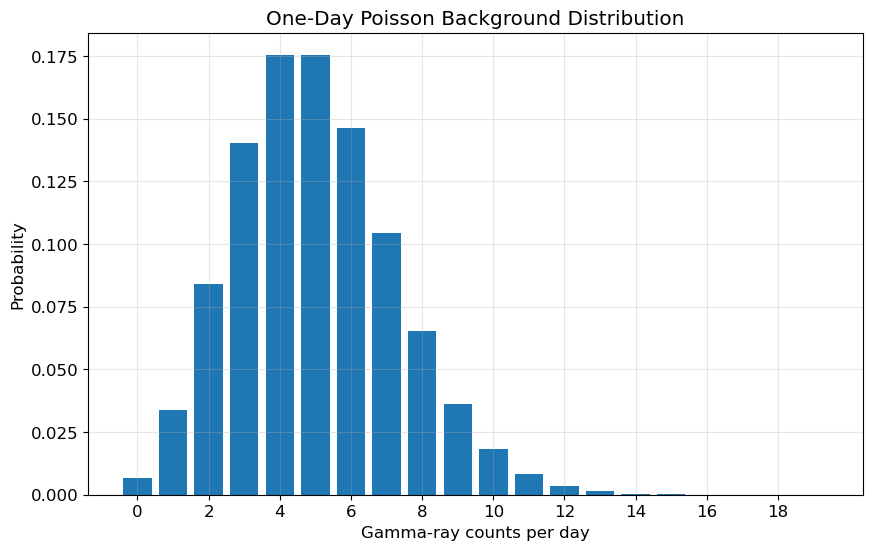

In [3]:
k = np.arange(0, 20)

p = stats.poisson.pmf(k, gr_background)

plt.bar(k, p)

plt.xlabel('Gamma-ray counts per day')
plt.ylabel('Probability')
plt.title('One-Day Poisson Background Distribution')
plt.xticks(np.arange(0, 20, 2))
plt.grid(alpha=0.3)
plt.show()

#### Problem 1.B & 1.C

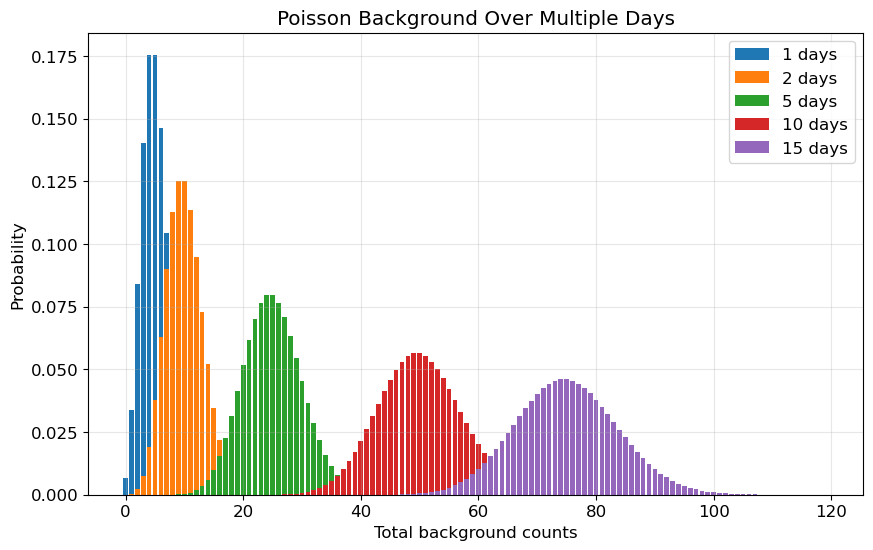

In [4]:
days = [1, 2, 5, 10, 15]

for n in days:
    mu = gr_background * n
    k = np.arange(0, 120)
    p = stats.poisson.pmf(k, mu)

    plt.bar(k, p, label=f'{n} days')

plt.xlabel('Total background counts')
plt.ylabel('Probability')
plt.title('Poisson Background Over Multiple Days')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

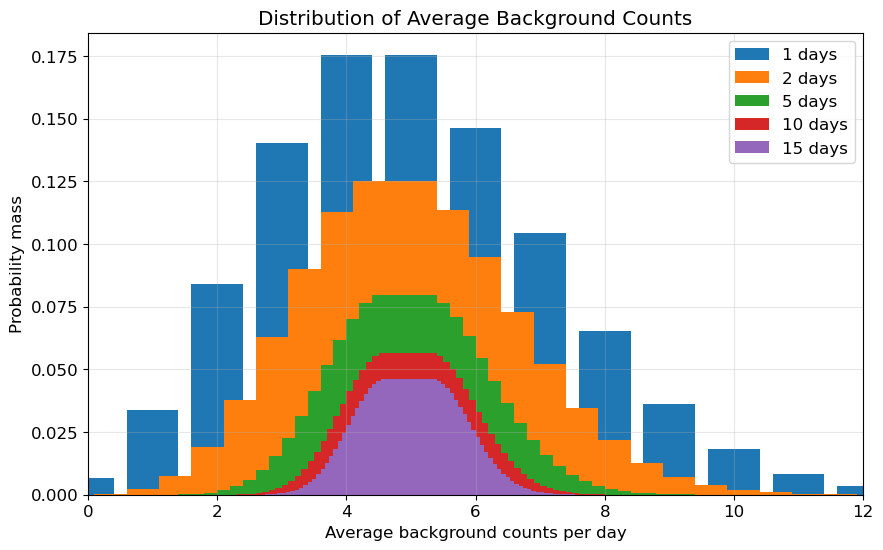

In [5]:
for n in days:
    mu = gr_background * n
    k = np.arange(0, 120)
    p = stats.poisson.pmf(k, mu)

    avg = k / n

    plt.bar(avg, p, label=f'{n} days')

plt.xlim(0, 12)
plt.xlabel('Average background counts per day')
plt.ylabel('Probability mass')
plt.title('Distribution of Average Background Counts')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

As we observe over more days, the expected average number of gamma-ray events remains at 5 per day, but our measurement of that average becomes more precise. Although the number of events detected on any individual day can fluctuate, averaging over more days reduces the effect of those fluctuations.

This is shown in Part C, where the distributions remain centered around 5 but become narrower as the number of observing days increases. This agrees with the Central Limit Theorem, which tells us that the distribution of averages approaches a Gaussian as we collect more independent observations.

This also agrees with Part B. While the total number of events increases with observing time, the expected average number of events per day remains constant. By observing for longer, we accumulate more events and obtain a better estimate of the underlying background rate.

#### Problem 1.D

In [6]:
n = 5

mu_background = gr_background * n
observed = gr_emitted * n

p_value = stats.poisson.sf(observed - 1, mu_background)
z = stats.norm.isf(p_value)

print(f"Probability: {p_value:.6e}")
print(f"Significance: {z:.3f} sigma")

Probability: 6.953305e-06
Significance: 4.345 sigma


#### Problem 2.A

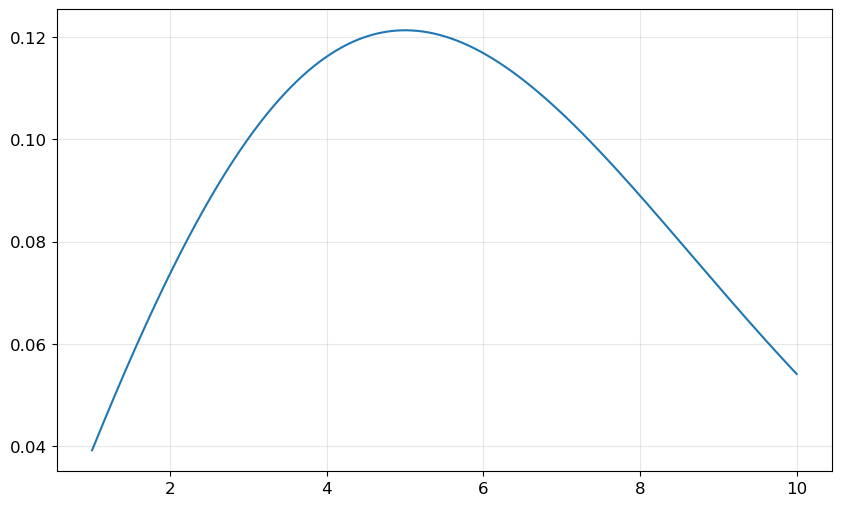

In [7]:
x = np.linspace(1, 10, 1000)
pdf = stats.rayleigh.pdf(x, scale=5)

plt.grid(alpha=0.3)
plt.plot(x, pdf);

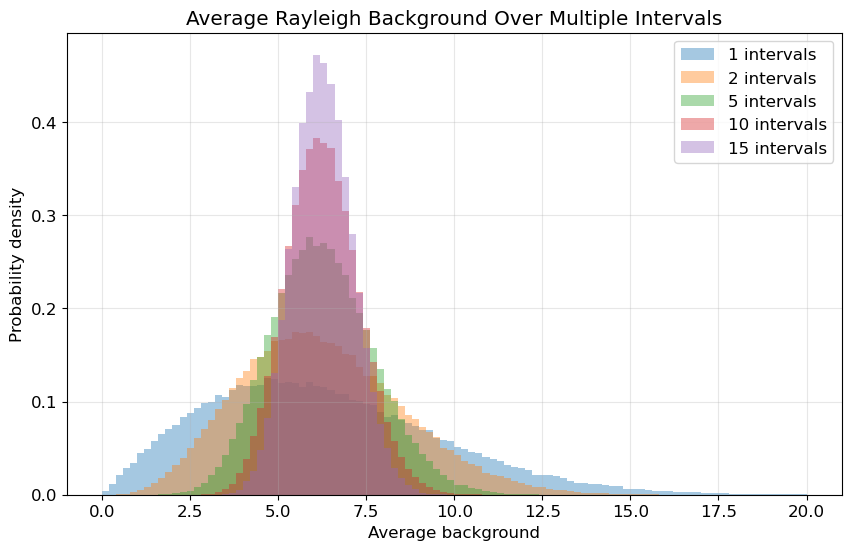

In [8]:
rng = np.random.default_rng(42)

intervals = [1, 2, 5, 10, 15]
samples = 100000
bins = np.linspace(0, 20, 101)

plt.figure(figsize=(10, 6))

for n in intervals:
    data = rng.rayleigh(scale=5, size=(samples, n))
    averages = np.mean(data, axis=1)

    plt.hist(averages, bins=bins, density=True,
             alpha=0.4, label=f'{n} intervals')

plt.xlabel('Average background')
plt.ylabel('Probability density')
plt.title('Average Rayleigh Background Over Multiple Intervals')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Problem 2.B
As we average over more intervals, the distribution becomes narrower and more symmetric while remaining centered around the same expected background value. The original Rayleigh distribution is skewed toward higher values, but averaging multiple observations reduces that. This is consistent with the Central Limit Theorem, which predicts that the distribution of averages approaches a Gaussian as the number of independent observations increases. From the plot, the distribution appears approximately Gaussian after around 10–15 intervals.

#### Problem 3.A

In [9]:
bg_sigma = 2
signal = 10

p_value = stats.norm.sf(signal, loc=0, scale=bg_sigma)

print(f"Background probability: {p_value:.6e}")

Background probability: 2.866516e-07


In [10]:
z = stats.norm.isf(p_value)

print(f"Significance: {z:.2f} sigma")

Significance: 5.00 sigma


For a Gaussian background with a mean of zero and a standard deviation of 2, an observed signal of 10 corresponds to a 5-sigma detection. The probability of the background alone producing a signal this strong or stronger is approximately $2.87\times10^{-7}$. Since the location of the signal was identified in advance using SWIFT, we only need to consider the probability of a random fluctuation in that single pixel.

#### Problem 3.B
If a random background fluctuation has a probability of approximately $2.87\times10^{-7}$ in one pixel, what happens to our chances of seeing such a fluctuation when we examine 10,000 independent pixels instead?

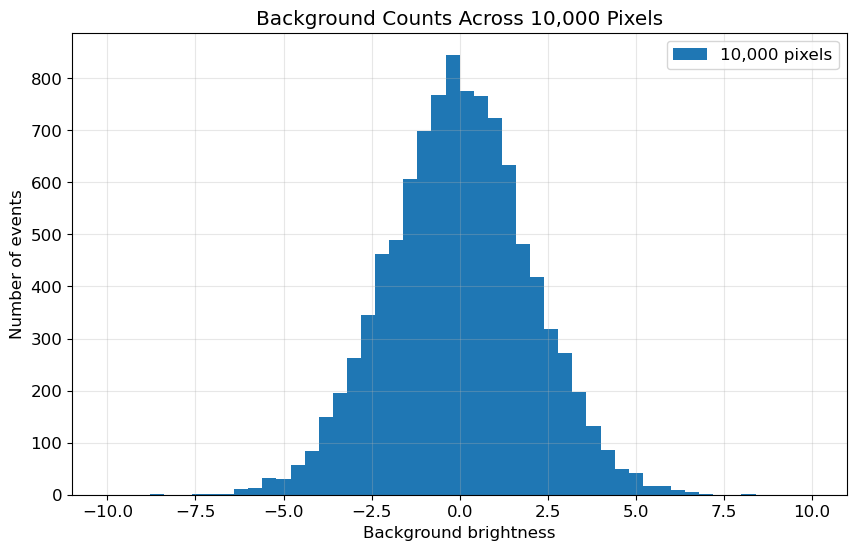

In [11]:
rng = np.random.default_rng(42)

many_pixels = rng.normal(0, bg_sigma, 10000)

bins = np.linspace(-10, 10, 51)

plt.hist(many_pixels, bins=bins,
         label='10,000 pixels')

plt.xlabel('Background brightness')
plt.ylabel('Number of events')
plt.title('Background Counts Across 10,000 Pixels')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

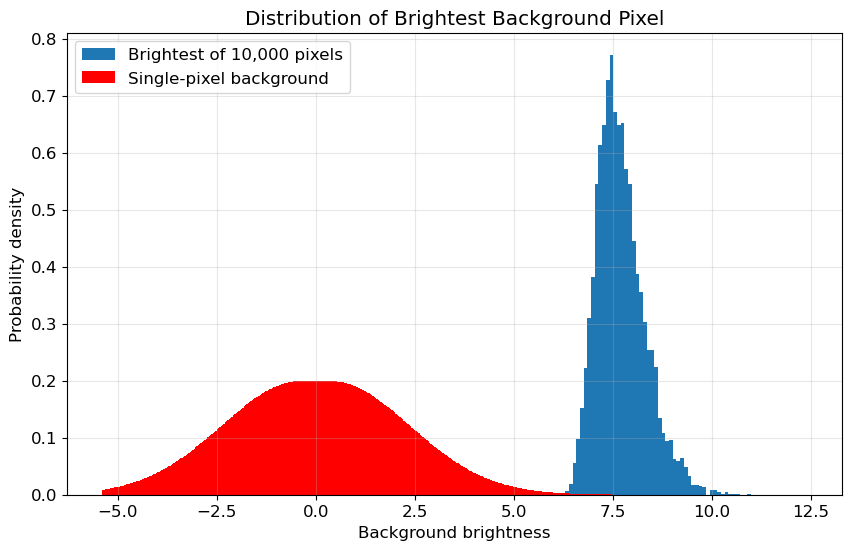

In [12]:
rng = np.random.default_rng(42)

max_values = []

for i in range(5000):
    pixels = rng.normal(0, bg_sigma, 10000)
    max_values.append(np.max(pixels))

x = np.linspace(-5, 12, 500)

plt.hist(max_values, bins=50, density=True,
        label='Brightest of 10,000 pixels')

plt.bar(x, stats.norm.pdf(x, 0, bg_sigma), color='red',
         label='Single-pixel background')

plt.xlabel('Background brightness')
plt.ylabel('Probability density')
plt.title('Distribution of Brightest Background Pixel')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

When searching 10,000 pixels instead of one, the background distribution of each individual pixel remains Gaussian. However, because we're examining so many pixels, we're much more likely to encounter a large random fluctuation somewhere in the image.

#### Problem 3.C

In [13]:
num_pixels = 10000

p_global = num_pixels * p_value
z_global = stats.norm.isf(p_global)

print(f"Single-pixel probability: {p_value:.6e}")
print(f"Single-pixel significance: {z:.2f} sigma")
print(f"10,000-pixel probability: {p_global:.6f}")
print(f"10,000-pixel significance: {z_global:.2f} sigma")

Single-pixel probability: 2.866516e-07
Single-pixel significance: 5.00 sigma
10,000-pixel probability: 0.002867
10,000-pixel significance: 2.76 sigma


When searching 10,000 pixels instead of one, the probability of finding a background fluctuation at least as strong as our observed signal increases by approximately a factor of 10,000. This increases the probability from $2.87\times10^{-7}$ to approximately 0.00287. Converting this probability back into sigma gives a significance of approximately 2.76 sigma, compared to the original 5 sigma from Problem 3.A. Although the brightness of our signal hasn't changed, its significance decreases because searching more pixels gives the background more opportunities to produce a large random fluctuation.